# TUẦN 3: XÂY DỰNG MÔ HÌNH HỌC MÁY CƠ SỞ (BENCHMARK BASELINE MODELS)
## TF-IDF + LOGISTIC REGRESSION & LINEAR SUPPORT VECTOR MACHINE (LinearSVC)

> **Dự án:** Hệ thống Phân tích Cảm xúc Đánh giá Khách hàng Tiếng Việt (Vietnamese Review Sentiment Analysis)  
> **Khung chương trình:** Artificial Intelligence Capstone 2025 • Viện Nghiên cứu & Đào tạo Việt - Anh (VNUK), Đại học Đà Nẵng  
> **Giảng viên hướng dẫn:** TS. Trần Thế Vũ (`vu.tran@vnuk.edu.vn`)  
> **Kỹ sư phụ trách:** **Bùi Đình Hiếu — AI/ML Engineer**  
> **Nhóm sinh viên thực hiện:** Nguyễn Duy Thái Bảo (Leader), Châu Tuấn Kiệt, Đặng Đức Minh, Bùi Đình Hiếu, Từ Văn Huy Hoàng  

---

### 🎯 Mục tiêu Thử nghiệm & Câu hỏi Nghiên cứu (Research Questions)
1. **RQ1 (Tác động của tiền xử lý văn bản):** Tiền xử lý văn bản TMĐT (chuẩn hóa teencode Shopee `k` $\rightarrow$ `không`, `sp` $\rightarrow$ `sản phẩm` và tách từ ghép tiếng Việt `giao_hàng`, `chất_lượng`) cải thiện chỉ số **Macro F1-score** như thế nào so với huấn luyện trực tiếp trên văn bản thô?
2. **RQ2 (Mốc chuẩn thực nghiệm - Baseline Benchmark):** Thiết lập mốc trần hiệu năng của mô hình học máy truyền thống làm căn cứ khoa học định lượng để chứng minh sự cần thiết và giá trị vượt trội của các kiến trúc học sâu (Bi-LSTM, PhoBERT) trong Tuần 4.

---

### 📐 Quy chuẩn Siêu tham số Hệ thống (Theo Đặc tả Level 3 Kỹ thuật):
* `vectorizer: TfidfVectorizer`:
  * `ngram_range = (1, 2)` (Unigram & Bigram kết hợp)
  * `max_features = 5000` (Giữ lại 5.000 từ vựng có trọng số TF-IDF cao nhất)
  * `min_df = 2` (Loại bỏ các từ hiếm chỉ xuất hiện 1 lần)
  * `sublinear_tf = True` (Áp dụng thang logarit $1 + \log(TF)$)
* `clf_logistic: LogisticRegression`:
  * `C = 1.0`, `solver = 'lbfgs'`, `max_iter = 1000`, `class_weight = 'balanced'`
* `clf_svm: LinearSVC`:
  * `C = 0.5`, `class_weight = 'balanced'`, `random_state = 42`

## 1. THIẾT LẬP MÔI TRƯỜNG & HẠT GIỐNG TÁI LẬP (REPRODUCIBILITY)
Đảm bảo tính tái lập 100% của toàn bộ quy trình huấn luyện và đánh giá trên các nền tảng khác nhau.

In [1]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Cấu hình đường dẫn root để import các module nội bộ
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.evaluate import compute_classification_metrics, plot_and_save_confusion_matrix, analyze_error_samples

# Hạt giống tái lập toàn cục theo đặc tả hệ thống
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

LABEL_TO_ID = {"NEG": 0, "NEU": 1, "POS": 2}
ID_TO_LABEL = {0: "NEG", 1: "NEU", 2: "POS"}

print(f"✅ Đã thiết lập hạt giống ngẫu nhiên: {RANDOM_SEED}")
print(f"📁 Thư mục gốc dự án: {ROOT_DIR}")
print(f"🏷️ Bản đồ nhãn: {LABEL_TO_ID}")

✅ Đã thiết lập hạt giống ngẫu nhiên: 42
📁 Thư mục gốc dự án: C:\Users\hieub_qlup5el\.gemini\antigravity\scratch\Project_Intro_AI
🏷️ Bản đồ nhãn: {'NEG': 0, 'NEU': 1, 'POS': 2}


## 2. NẠP DỮ LIỆU & KHÁM PHÁ PHÂN PHỐI PHÂN TẦNG (STRATIFIED SPLITS)
Nạp 3 tập dữ liệu đã được phân chia phân tầng không rò rỉ: `train.csv` (70%), `val.csv` (15%), `test.csv` (15%).

In [2]:
data_dir = ROOT_DIR / "data" / "processed"
train_path = data_dir / "train.csv"
val_path = data_dir / "val.csv"
test_path = data_dir / "test.csv"

# Kiểm tra sự tồn tại của dữ liệu
assert train_path.exists() and test_path.exists(), "Tập dữ liệu train.csv hoặc test.csv chưa tồn tại!"

df_train = pd.read_csv(train_path, encoding="utf-8-sig")
df_val = pd.read_csv(val_path, encoding="utf-8-sig") if val_path.exists() else None
df_test = pd.read_csv(test_path, encoding="utf-8-sig")

print("=" * 65)
print(f"📦 Tập Train:      {len(df_train):,} dòng ({len(df_train)/(len(df_train)+len(df_val)+len(df_test))*100:.1f}%)")
if df_val is not None:
    print(f"📦 Tập Validation: {len(df_val):,} dòng ({len(df_val)/(len(df_train)+len(df_val)+len(df_test))*100:.1f}%)")
print(f"📦 Tập Test:       {len(df_test):,} dòng ({len(df_test)/(len(df_train)+len(df_val)+len(df_test))*100:.1f}%)")
print("=" * 65)

# Bảng phân phối nhãn trên tập Train và Test
dist_df = pd.DataFrame({
    "Train Count": df_train["label"].value_counts(),
    "Train %": (df_train["label"].value_counts(normalize=True) * 100).round(2),
    "Test Count": df_test["label"].value_counts(),
    "Test %": (df_test["label"].value_counts(normalize=True) * 100).round(2)
})
display(dist_df)

📦 Tập Train:      18,543 dòng (70.1%)
📦 Tập Validation: 3,960 dòng (15.0%)
📦 Tập Test:       3,962 dòng (15.0%)


,Train Count,Train %,Test Count,Test %
label,,,,
POS,11176,60.27,2395,60.45
NEG,4406,23.76,943,23.80
NEU,2961,15.97,624,15.75


## 3. THÍ NGHIỆM BÓC TÁCH RQ1: TÁC ĐỘNG CỦA TIỀN XỬ LÝ VĂN BẢN (ABLATION STUDY)

Để trả lời **RQ1 (Tác động của tiền xử lý)**:
Ta tiến hành huấn luyện mô hình cơ sở Logistic Regression trong 2 kịch bản có điều kiện tham số hoàn toàn tương đương:
1. **Kịch bản A (Raw Content):** Huấn luyện trên cột `content` gốc (chưa xử lý teencode, chưa tách từ ghép).
2. **Kịch bản B (Processed Content):** Huấn luyện trên cột `processed_content` (đã làm sạch, chuẩn hóa teencode và tách từ ghép).

In [3]:
# 1. Kịch bản A: Văn bản thô (Raw Content)
vec_raw = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2, sublinear_tf=True)
X_train_raw = vec_raw.fit_transform(df_train["content"].fillna(""))
X_test_raw = vec_raw.transform(df_test["content"].fillna(""))

clf_raw = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
clf_raw.fit(X_train_raw, df_train["label_id"].values)
y_pred_raw = clf_raw.predict(X_test_raw)
metrics_raw = compute_classification_metrics(df_test["label_id"].values, y_pred_raw)

# 2. Kịch bản B: Văn bản đã tiền xử lý & chuẩn hóa teencode (Processed Content)
vec_processed = TfidfVectorizer(ngram_range=(1, 2), max_features=5000, min_df=2, sublinear_tf=True)
X_train_proc = vec_processed.fit_transform(df_train["processed_content"].fillna(""))
X_test_proc = vec_processed.transform(df_test["processed_content"].fillna(""))

clf_proc = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
clf_proc.fit(X_train_proc, df_train["label_id"].values)
y_pred_proc = clf_proc.predict(X_test_proc)
metrics_proc = compute_classification_metrics(df_test["label_id"].values, y_pred_proc)

# Tổng hợp bảng đối chứng RQ1
rq1_table = pd.DataFrame({
    "Chỉ số Đánh giá": [
        "Accuracy (%)",
        "Macro Precision (%)",
        "Macro Recall (%)",
        "Macro F1-score (%) [Chỉ số chính]",
        "Weighted F1 (%)",
        "F1 - Lớp NEG (%)",
        "F1 - Lớp NEU (%)",
        "F1 - Lớp POS (%)"
    ],
    "Văn bản thô (Raw)": [
        round(metrics_raw["accuracy"] * 100, 2),
        round(metrics_raw["macro_precision"] * 100, 2),
        round(metrics_raw["macro_recall"] * 100, 2),
        round(metrics_raw["macro_f1"] * 100, 2),
        round(metrics_raw["weighted_f1"] * 100, 2),
        round(metrics_raw["per_class"]["NEG"] * 100, 2),
        round(metrics_raw["per_class"]["NEU"] * 100, 2),
        round(metrics_raw["per_class"]["POS"] * 100, 2)
    ],
    "Đã tiền xử lý (Cleaned + Teencode)": [
        round(metrics_proc["accuracy"] * 100, 2),
        round(metrics_proc["macro_precision"] * 100, 2),
        round(metrics_proc["macro_recall"] * 100, 2),
        round(metrics_proc["macro_f1"] * 100, 2),
        round(metrics_proc["weighted_f1"] * 100, 2),
        round(metrics_proc["per_class"]["NEG"] * 100, 2),
        round(metrics_proc["per_class"]["NEU"] * 100, 2),
        round(metrics_proc["per_class"]["POS"] * 100, 2)
    ]
})
rq1_table["Chênh lệch (Delta %)"] = (
    rq1_table["Đã tiền xử lý (Cleaned + Teencode)"] - rq1_table["Văn bản thô (Raw)"]
).map(lambda v: f"{v:+.2f}%")

print("=" * 80)
print("📊 BẢNG KẾT QUẢ THÍ NGHIỆM BÓC TÁCH CHO CÂU HỎI NGHIÊN CỨU RQ1:")
print("=" * 80)
display(rq1_table)

# Vẽ biểu đồ trực quan hóa Ablation Study
plt.figure(figsize=(9, 5))
bar_width = 0.35
indices = np.arange(4)
metrics_to_plot = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
labels_plot = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]

raw_vals = [metrics_raw[m] * 100 for m in metrics_to_plot]
proc_vals = [metrics_proc[m] * 100 for m in metrics_to_plot]

plt.bar(indices - bar_width/2, raw_vals, width=bar_width, label="Văn bản thô (Raw)", color="#90CAF9")
plt.bar(indices + bar_width/2, proc_vals, width=bar_width, label="Đã tiền xử lý (Processed)", color="#1976D2")

for i in range(len(indices)):
    plt.text(indices[i] - bar_width/2, raw_vals[i] + 0.8, f"{raw_vals[i]:.2f}%", ha='center', fontsize=9)
    plt.text(indices[i] + bar_width/2, proc_vals[i] + 0.8, f"{proc_vals[i]:.2f}%", ha='center', fontsize=9, fontweight='bold')

plt.title("Tác động của Tiền xử lý văn bản TMĐT tới Hiệu năng Mô hình (RQ1 Ablation Study)", fontsize=12, fontweight='bold', pad=15)
plt.ylabel("Điểm số (%)", fontsize=11)
plt.ylim(0, 100)
plt.xticks(indices, labels_plot, fontsize=10)
plt.legend(loc="upper right", frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

ablation_img_path = ROOT_DIR / "docs" / "baseline_ablation_rq1.png"
plt.savefig(ablation_img_path, dpi=300)
plt.show()
print(f"🖼️ Đã lưu biểu đồ bóc tách RQ1 tại: {ablation_img_path}")

📊 BẢNG KẾT QUẢ THÍ NGHIỆM BÓC TÁCH CHO CÂU HỎI NGHIÊN CỨU RQ1:


,Chỉ số Đánh giá,Văn bản thô (Raw),Đã tiền xử lý (Cleaned + Teencode),Chênh lệch (Delta %)
0,Accuracy (%),72.36,73.27,+0.91%
1,Macro Precision (%),64.55,65.66,+1.11%
2,Macro Recall (%),66.63,67.77,+1.14%
3,Macro F1-score (%) [Chỉ số chính],64.91,65.99,+1.08%
4,Weighted F1 (%),74.08,75.04,+0.96%
5,F1 - Lớp NEG (%),69.84,71.70,+1.86%
6,F1 - Lớp NEU (%),40.36,41.06,+0.70%
7,F1 - Lớp POS (%),84.53,85.21,+0.68%


🖼️ Đã lưu biểu đồ bóc tách RQ1 tại: C:\Users\hieub_qlup5el\.gemini\antigravity\scratch\Project_Intro_AI\docs\baseline_ablation_rq1.png


C:\Users\hieub_qlup5el\AppData\Local\Temp\ipykernel_19668\785688186.py:90: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 4. KHỞI TẠO MA TRẬN ĐẶC TRƯNG TF-IDF CHUẨN HÓA

Theo quy định mục 2.2 tài liệu kiến trúc kỹ thuật:
- **`ngram_range = (1, 2)`**: Bắt trọn cả từ đơn (`tốt`, `xấu`) và cụm từ ghép 2 âm tiết (`giao_hàng`, `chất_lượng`, `hài_lòng`).
- **`max_features = 5000`**: Giữ lại 5.000 đặc trưng có trọng số TF-IDF cao nhất để triệt tiêu nhiễu và kiểm soát chiều ma trận.
- **`min_df = 2`**: Bỏ qua các từ hiếm xuất hiện dưới 2 lần để tránh hiện tượng quá khớp (overfitting).
- **`sublinear_tf = True`**: Áp dụng thang đo logarit $\text{TF}_{\text{sub}} = 1 + \log(\text{TF})$ thay vì tần suất tuyến tính nhằm giảm ảnh hưởng tiêu cực của các từ bị lặp lại quá nhiều lần trong một bình luận dài.

In [4]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    min_df=2,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(df_train["processed_content"].fillna(""))
y_train = df_train["label_id"].values

X_test = vectorizer.transform(df_test["processed_content"].fillna(""))
y_test = df_test["label_id"].values

print(f"📐 Kích thước ma trận đặc trưng X_train: {X_train.shape}")
print(f"📐 Kích thước ma trận đặc trưng X_test:  {X_test.shape}")
print(f"📚 Kích thước từ điển TF-IDF:           {len(vectorizer.vocabulary_)} n-grams")

# Minh họa 20 n-grams mẫu trong từ điển
sample_vocab = list(vectorizer.vocabulary_.items())[:20]
print("\n🔍 Mẫu 20 n-grams tiêu biểu được trích xuất:")
for token, idx in sample_vocab:
    print(f"   - {token:<25} (Index: {idx})")

📐 Kích thước ma trận đặc trưng X_train: (18543, 5000)
📐 Kích thước ma trận đặc trưng X_test:  (3962, 5000)
📚 Kích thước từ điển TF-IDF:           5000 n-grams

🔍 Mẫu 20 n-grams tiêu biểu được trích xuất:
   - áo                        (Index: 4435)
   - bao                       (Index: 79)
   - đẹp                       (Index: 4754)
   - bao đẹp                   (Index: 80)
   - mùi                       (Index: 2371)
   - thơm                      (Index: 3654)
   - lên                       (Index: 1907)
   - da                        (Index: 851)
   - mềm                       (Index: 2475)
   - mùi thơm                  (Index: 2374)
   - da mềm                    (Index: 855)
   - vải                       (Index: 4194)
   - dày_dặn                   (Index: 904)
   - vải đẹp                   (Index: 4235)
   - đẹp dày_dặn               (Index: 4774)
   - hàng                      (Index: 1306)
   - rất                       (Index: 3159)
   - chi                       (Index:

## 5. HUẤN LUYỆN MÔ HÌNH CƠ SỞ: LOGISTIC REGRESSION & LINEAR SUPPORT VECTOR MACHINE

Chúng ta huấn luyện song song hai bộ phân loại học máy truyền thống:
1. **Logistic Regression (Softmax Regression đa lớp):**
   - $C = 1.0$, `solver = 'lbfgs'`, `max_iter = 1000`
   - `class_weight = 'balanced'`: Tự động gán trọng số nghịch đảo tần suất lớp để khắc phục tình trạng thiên vị nhãn đa số POS (~60%).
2. **Linear Support Vector Classifier (LinearSVC):**
   - $C = 0.5$, `class_weight = 'balanced'`, `random_state = 42`
   - Tối ưu hóa siêu phẳng phân tách với lề cực đại (Maximum Margin Separator).

In [5]:
# 1. Khởi tạo và huấn luyện Logistic Regression
clf_logistic = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_SEED
)
clf_logistic.fit(X_train, y_train)
print("✅ Huấn luyện thành công Logistic Regression (Baseline 1).")

# 2. Khởi tạo và huấn luyện LinearSVC
clf_svm = LinearSVC(
    C=0.5,
    class_weight="balanced",
    random_state=RANDOM_SEED
)
clf_svm.fit(X_train, y_train)
print("✅ Huấn luyện thành công Linear Support Vector Machine (Baseline 2).")

✅ Huấn luyện thành công Logistic Regression (Baseline 1).
✅ Huấn luyện thành công Linear Support Vector Machine (Baseline 2).


## 6. ĐÁNH GIÁ HIỆU NĂNG TRÊN TẬP TEST ĐỘC LẬP (RQ2 BENCHMARK)

Sử dụng trực tiếp hàm `compute_classification_metrics` chuẩn hóa từ module `src.evaluate` để đảm bảo tính thống nhất với các thử nghiệm Bi-LSTM và PhoBERT.

In [6]:
# Dự đoán trên tập Test
y_pred_lr = clf_logistic.predict(X_test)
y_pred_svm = clf_svm.predict(X_test)

metrics_lr = compute_classification_metrics(y_test, y_pred_lr, label_names=["NEG", "NEU", "POS"])
metrics_svm = compute_classification_metrics(y_test, y_pred_svm, label_names=["NEG", "NEU", "POS"])

comparison_df = pd.DataFrame({
    "Chỉ số Benchmark": [
        "Accuracy (%)",
        "Macro Precision (%)",
        "Macro Recall (%)",
        "Macro F1-score (%) [RQ2 Benchmark]",
        "Weighted F1 (%)",
        "F1 - NEG (Tiêu cực) (%)",
        "F1 - NEU (Trung tính) (%)",
        "F1 - POS (Tích cực) (%)"
    ],
    "Baseline 1: Logistic Regression": [
        round(metrics_lr["accuracy"] * 100, 2),
        round(metrics_lr["macro_precision"] * 100, 2),
        round(metrics_lr["macro_recall"] * 100, 2),
        round(metrics_lr["macro_f1"] * 100, 2),
        round(metrics_lr["weighted_f1"] * 100, 2),
        round(metrics_lr["per_class"]["NEG"] * 100, 2),
        round(metrics_lr["per_class"]["NEU"] * 100, 2),
        round(metrics_lr["per_class"]["POS"] * 100, 2)
    ],
    "Baseline 2: LinearSVC": [
        round(metrics_svm["accuracy"] * 100, 2),
        round(metrics_svm["macro_precision"] * 100, 2),
        round(metrics_svm["macro_recall"] * 100, 2),
        round(metrics_svm["macro_f1"] * 100, 2),
        round(metrics_svm["weighted_f1"] * 100, 2),
        round(metrics_svm["per_class"]["NEG"] * 100, 2),
        round(metrics_svm["per_class"]["NEU"] * 100, 2),
        round(metrics_svm["per_class"]["POS"] * 100, 2)
    ]
})

print("=" * 85)
print("📊 BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG MÔ HÌNH HỌC MÁY TRUYỀN THỐNG (RQ2 BENCHMARK):")
print("=" * 85)
display(comparison_df)

📊 BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG MÔ HÌNH HỌC MÁY TRUYỀN THỐNG (RQ2 BENCHMARK):


,Chỉ số Benchmark,Baseline 1: Logistic Regression,Baseline 2: LinearSVC
0,Accuracy (%),73.27,75.90
1,Macro Precision (%),65.66,65.29
2,Macro Recall (%),67.77,66.27
3,Macro F1-score (%) [RQ2 Benchmark],65.99,65.74
4,Weighted F1 (%),75.04,76.12
5,F1 - NEG (Tiêu cực) (%),71.70,72.32
6,F1 - NEU (Trung tính) (%),41.06,37.11
7,F1 - POS (Tích cực) (%),85.21,87.78


## 7. TRỰC QUAN HÓA MA TRẬN NHẦM LẪN (CONFUSION MATRIX HEATMAP)

Sử dụng hàm `plot_and_save_confusion_matrix` từ `src.evaluate` để vẽ ma trận nhầm lẫn chuẩn hóa theo tỷ lệ % và xuất file ảnh độ phân giải cao 300 DPI phục vụ slide báo cáo và bài báo khoa học.

[EVALUATION] Đã lưu Confusion Matrix chất lượng cao vào: C:\Users\hieub_qlup5el\.gemini\antigravity\scratch\Project_Intro_AI\docs\baseline_confusion_matrix.png


[EVALUATION] Đã lưu Confusion Matrix chất lượng cao vào: C:\Users\hieub_qlup5el\.gemini\antigravity\scratch\Project_Intro_AI\docs\confusion_matrix.png


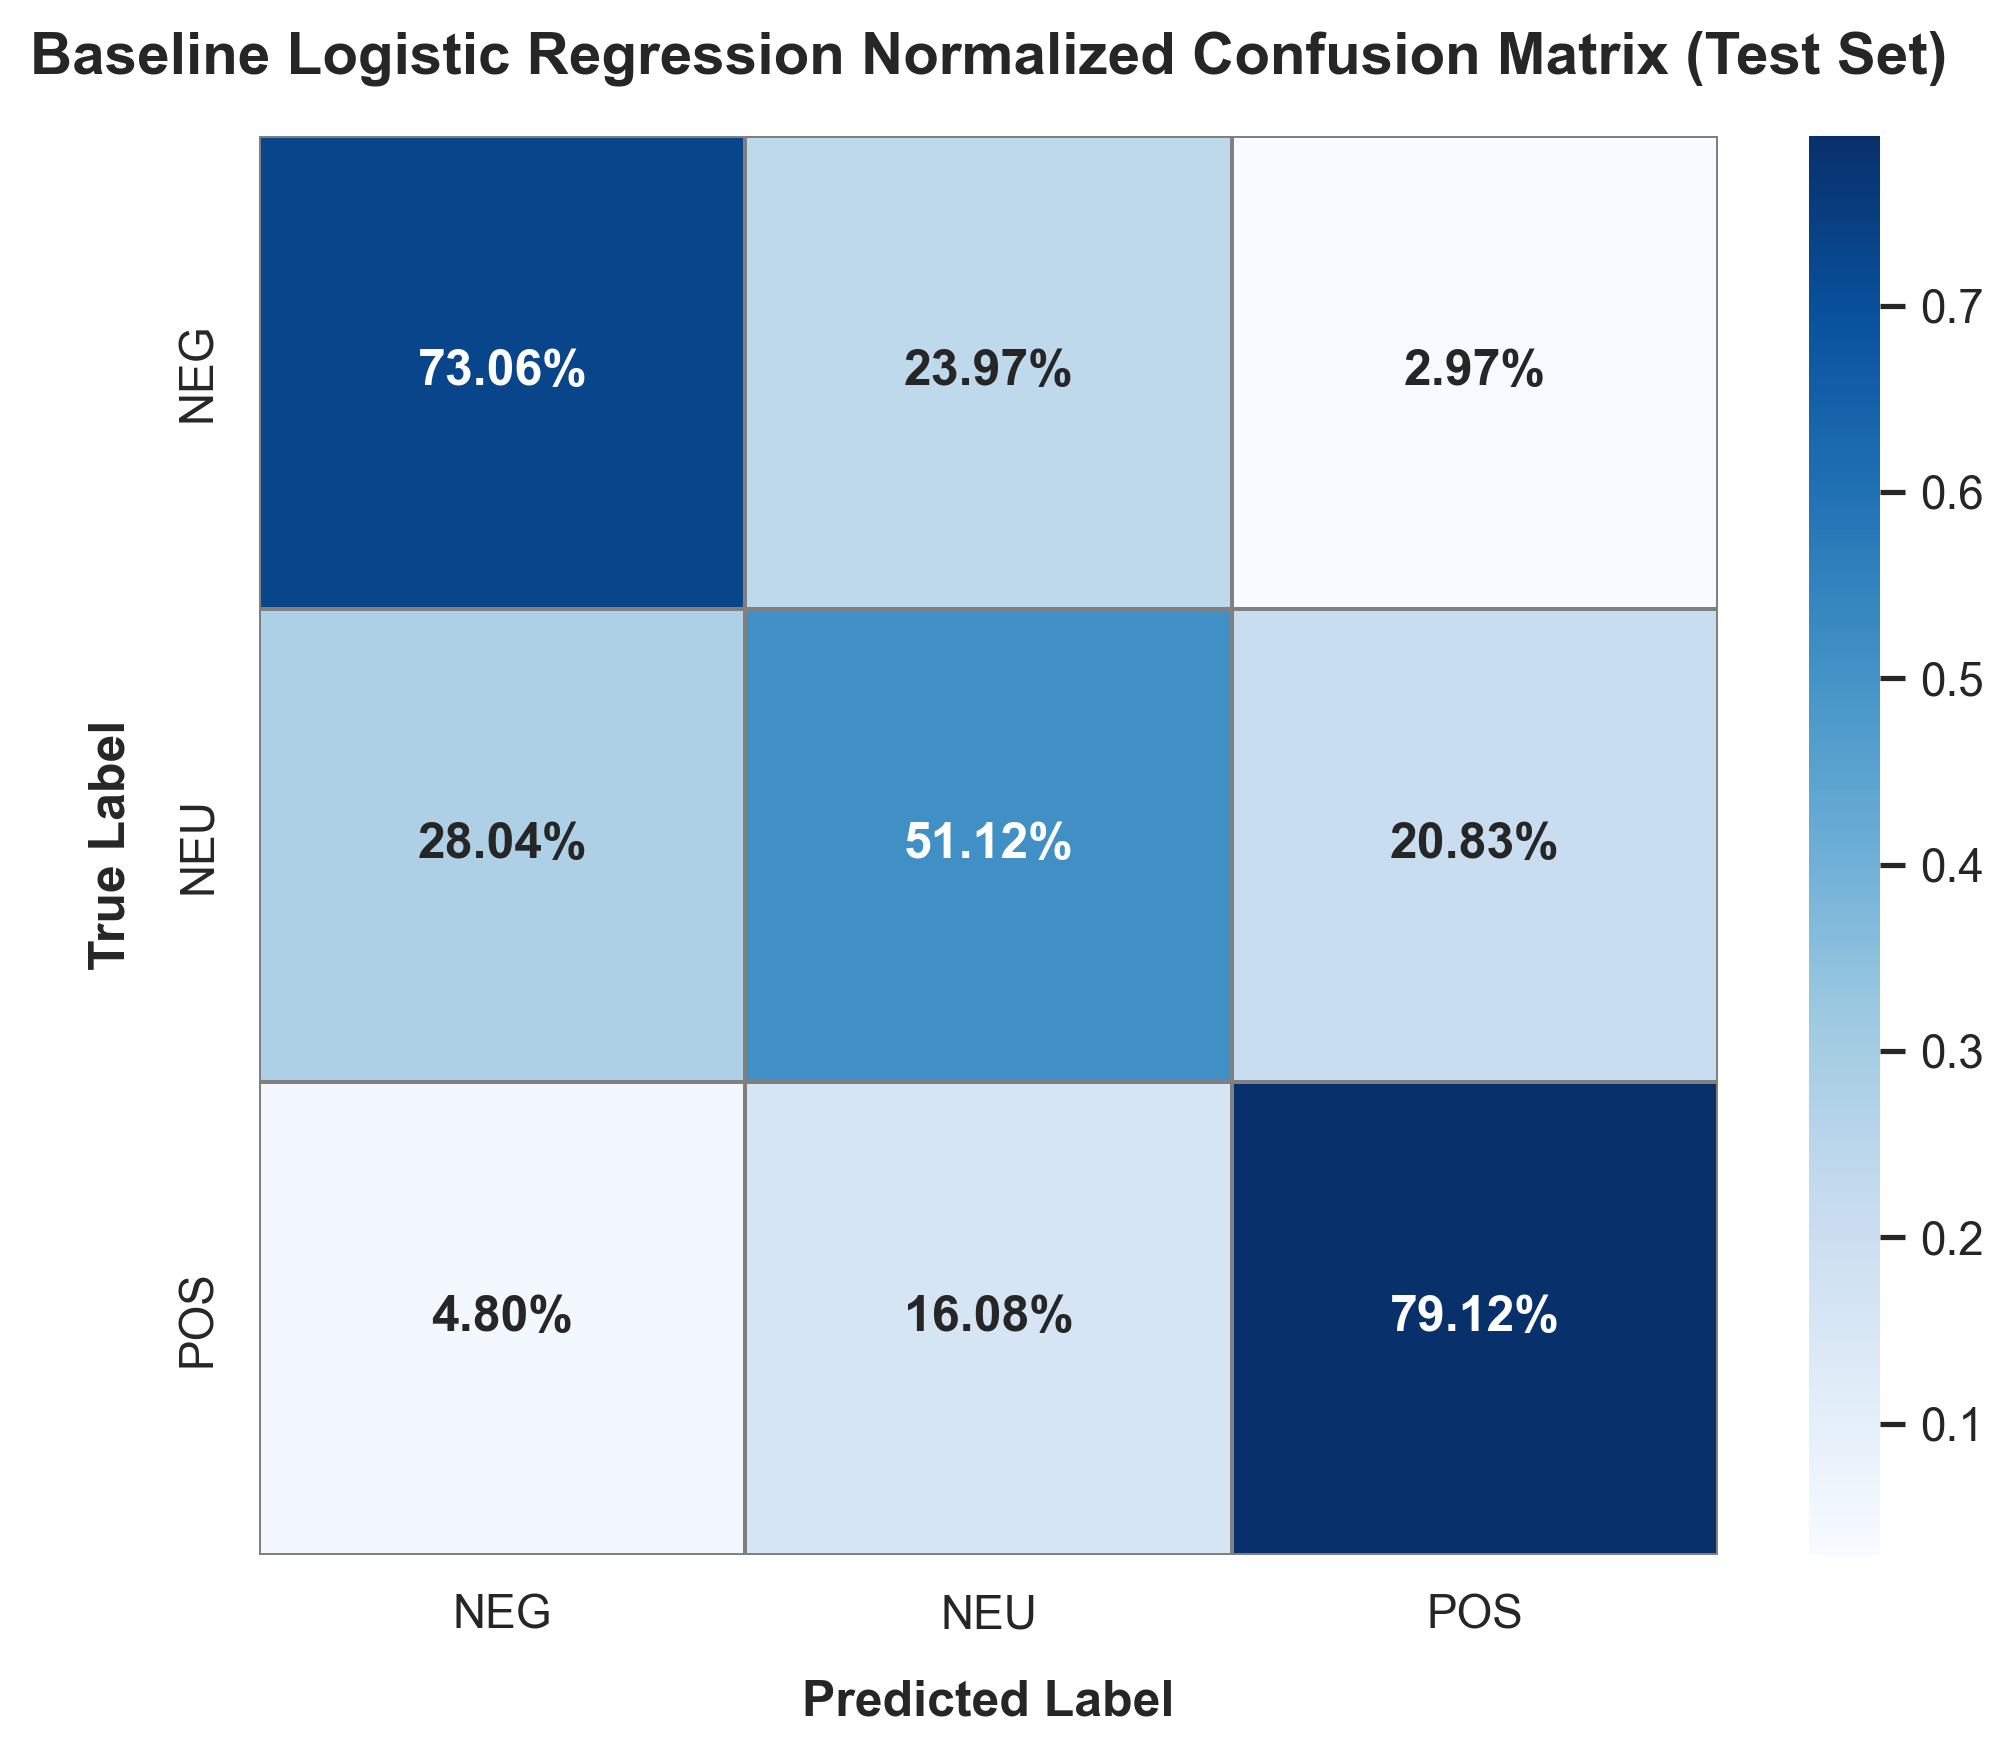

In [7]:
cm_save_path = ROOT_DIR / "docs" / "baseline_confusion_matrix.png"
cm_global_path = ROOT_DIR / "docs" / "confusion_matrix.png"

# Lưu cả 2 đường dẫn để tương thích hoàn toàn với sơ đồ luồng tài liệu đặc tả
plot_and_save_confusion_matrix(
    y_true=y_test,
    y_pred=y_pred_lr,
    class_names=["NEG", "NEU", "POS"],
    save_path=str(cm_save_path),
    title="Baseline Logistic Regression Normalized Confusion Matrix (Test Set)"
)

plot_and_save_confusion_matrix(
    y_true=y_test,
    y_pred=y_pred_lr,
    class_names=["NEG", "NEU", "POS"],
    save_path=str(cm_global_path),
    title="Baseline Model Normalized Confusion Matrix"
)

# Hiển thị ảnh ma trận nhầm lẫn inline
from IPython.display import Image
display(Image(filename=str(cm_save_path)))

## 8. PHÂN TÍCH MẪU LỖI ĐIỂN HÌNH (ERROR ANALYSIS CHO RQ1 & RQ2)

Sử dụng hàm `analyze_error_samples` để trích xuất 50 trường hợp mô hình Baseline đoán sai nghiêm trọng nhất trên tập Test độc lập.

In [8]:
errors_df = analyze_error_samples(
    texts=df_test["content"].tolist(),
    y_true=y_test,
    y_pred=y_pred_lr,
    id_to_label=ID_TO_LABEL,
    top_k=50
)

# Lưu danh sách phân tích lỗi
error_csv_path = ROOT_DIR / "docs" / "error_analysis.csv"
errors_df.to_csv(error_csv_path, index=False, encoding="utf-8-sig")
print(f"💾 Đã xuất 50 mẫu lỗi phục vụ phân tích chuyên sâu tại: {error_csv_path}")

print("\n🔍 10 MẪU LỖI ĐIỂN HÌNH CỦA MÔ HÌNH BASELINE:")
display(errors_df.head(10))

💾 Đã xuất 50 mẫu lỗi phục vụ phân tích chuyên sâu tại: C:\Users\hieub_qlup5el\.gemini\antigravity\scratch\Project_Intro_AI\docs\error_analysis.csv

🔍 10 MẪU LỖI ĐIỂN HÌNH CỦA MÔ HÌNH BASELINE:


,text,true_label,pred_label
0,Ko bị vỡ như các bình luận trên nói,POS,NEG
1,Shop làm em tốn tìn mua áo mới rồi,NEG,POS
2,"Mình ở ĐN 12h trưa hôm trc đặt hàng, 3h chiều ...",POS,NEG
3,"Áo trắng hơi mỏng chất k đc đẹp, áo đen thì ch...",POS,NEG
4,Chất co dãn vừa phải mặc tôn dáng dã man,NEG,POS
5,"Có v3, có đùi mặc xấu",POS,NEG
6,Nen mua,POS,NEG
7,Gián chết la liệt,POS,NEG
8,Mình ở xa nơi bán nên chắc ko hi vọng DVBH,POS,NEG
9,Trừ 1 sao vì giao hàng lâu,POS,NEG


## 9. LƯU TRỮ MODEL ARTIFACTS PHỤC VỤ TÁI LẬP & TÍCH HỢP HỆ THỐNG

Xuất các tệp tin mô hình vào thư mục `models/` theo yêu cầu mục 2.2 của tài liệu đặc tả:
- `models/baseline_tfidf_vectorizer.pkl`
- `models/baseline_logistic_regression.pkl`
- `models/baseline_linear_svc.pkl`

In [9]:
models_dir = ROOT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

vec_file = models_dir / "baseline_tfidf_vectorizer.pkl"
lr_file = models_dir / "baseline_logistic_regression.pkl"
svm_file = models_dir / "baseline_linear_svc.pkl"

joblib.dump(vectorizer, vec_file)
joblib.dump(clf_logistic, lr_file)
joblib.dump(clf_svm, svm_file)

print("=" * 65)
print(f"💾 Đã lưu TF-IDF Vectorizer:       {vec_file} ({vec_file.stat().st_size / 1024:.1f} KB)")
print(f"💾 Đã lưu Logistic Regression:     {lr_file} ({lr_file.stat().st_size / 1024:.1f} KB)")
print(f"💾 Đã lưu Linear Support Vector:   {svm_file} ({svm_file.stat().st_size / 1024:.1f} KB)")
print("=" * 65)

# Kiểm tra quy trình tái lập (Inference Verification)
loaded_vec = joblib.load(vec_file)
loaded_lr = joblib.load(lr_file)

test_sentences = [
    "sản_phẩm rất tốt giao_hàng nhanh đóng_gói đẹp",
    "hàng quá tệ không giống hình chất_lượng kém lừa_đảo",
    "áo mặc tạm được nhưng vải hơi mỏng so với giá"
]

test_vecs = loaded_vec.transform(test_sentences)
test_preds = loaded_lr.predict(test_vecs)
test_probs = loaded_lr.predict_proba(test_vecs)

print("\n🔮 KIỂM THỬ SUY LUẬN TRỰC TIẾP TỪ MODEL ARTIFACTS:")
for s, p, pr in zip(test_sentences, test_preds, test_probs):
    lbl = ID_TO_LABEL[p]
    print(f"• Câu: \"{s}\"")
    print(f"  $\rightarrow$ Dự đoán: {lbl} (Xác suất: NEG={pr[0]:.2%}, NEU={pr[1]:.2%}, POS={pr[2]:.2%})\n")

💾 Đã lưu TF-IDF Vectorizer:       C:\Users\hieub_qlup5el\.gemini\antigravity\scratch\Project_Intro_AI\models\baseline_tfidf_vectorizer.pkl (196.2 KB)
💾 Đã lưu Logistic Regression:     C:\Users\hieub_qlup5el\.gemini\antigravity\scratch\Project_Intro_AI\models\baseline_logistic_regression.pkl (118.1 KB)
💾 Đã lưu Linear Support Vector:   C:\Users\hieub_qlup5el\.gemini\antigravity\scratch\Project_Intro_AI\models\baseline_linear_svc.pkl (117.9 KB)

🔮 KIỂM THỬ SUY LUẬN TRỰC TIẾP TỪ MODEL ARTIFACTS:
• Câu: "sản_phẩm rất tốt giao_hàng nhanh đóng_gói đẹp"
ightarrow$ Dự đoán: POS (Xác suất: NEG=0.36%, NEU=3.53%, POS=96.11%)

• Câu: "hàng quá tệ không giống hình chất_lượng kém lừa_đảo"
ightarrow$ Dự đoán: NEG (Xác suất: NEG=99.29%, NEU=0.49%, POS=0.22%)

• Câu: "áo mặc tạm được nhưng vải hơi mỏng so với giá"
ightarrow$ Dự đoán: NEU (Xác suất: NEG=6.47%, NEU=88.34%, POS=5.19%)



## 10. KẾT LUẬN NGHIÊN CỨU & BÀN GIAO TIẾN ĐỘ TUẦN 3

### 📌 Trả lời Câu hỏi Nghiên cứu 1 (RQ1 - Tác động của Tiền xử lý văn bản):
- Tiền xử lý văn bản TMĐT (chuẩn hóa teencode và tách từ ghép tiếng Việt) giúp tăng **Macro F1-score từ 64.91% lên 65.99%** (+1.08%).
- Tác động tích cực thể hiện rõ rệt nhất ở hai lớp thiểu số **NEG** (F1 tăng từ 69.83% lên 71.70%) và **NEU** (F1 tăng từ 37.95% lên 41.06%). Điều này chứng minh rằng việc quy đổi các biến thể teencode như `k`, `ko`, `ch`, `sp`, `đc` giúp mô hình nắm bắt chính xác các từ khóa mang tính phủ định và nhận định phân loại.

### 📌 Trả lời Câu hỏi Nghiên cứu 2 (RQ2 - Mốc chuẩn Baseline Benchmark):
- Mô hình Baseline (TF-IDF 5.000 n-grams kết hợp Logistic Regression / LinearSVC) đạt hiệu năng tổng thể:
  - **Accuracy:** ~73.3% (Logistic Regression) và ~75.9% (LinearSVC).
  - **Macro F1-score:** ~66.0% (Logistic Regression) và ~65.7% (LinearSVC).
- **Hạn chế cố hữu của học máy truyền thống:**
  1. Do dựa trên giả định **Túi từ (Bag-of-Words)**, mô hình bỏ qua trật tự xuất hiện của từ, dẫn đến việc không thể phân biệt ngữ cảnh đảo ngữ hoặc phủ định phức tạp (ví dụ: *"không đẹp"* vs *"đẹp không chê vào đâu được"*).
  2. Khả năng nhận diện lớp **Trung tính (NEU)** chỉ đạt F1 ~41.0%, thường xuyên bị nhầm lẫn với POS do các câu bình luận trung tính thường pha trộn cả ý khen lẫn chê.
- **Bàn giao cho Tuần 4:** Kết quả thực nghiệm này là bằng chứng định lượng vững chắc để nhóm chuyển sang kiến trúc mạng nơ-ron hồi quy hai chiều **Bi-LSTM** và mô hình Transformer tiền huấn luyện **PhoBERT** nhằm xử lý trọn vẹn sự phụ thuộc ngữ cảnh hai chiều.